Hourly records: 70091  Training: 56072  Testing: 14019
Epoch 1  Loss = 0.16267
Epoch 2  Loss = 0.01492
Epoch 3  Loss = 0.01077
ARIMA(2,1,1) RMSE: 0.814
LSTM RMSE: 0.858


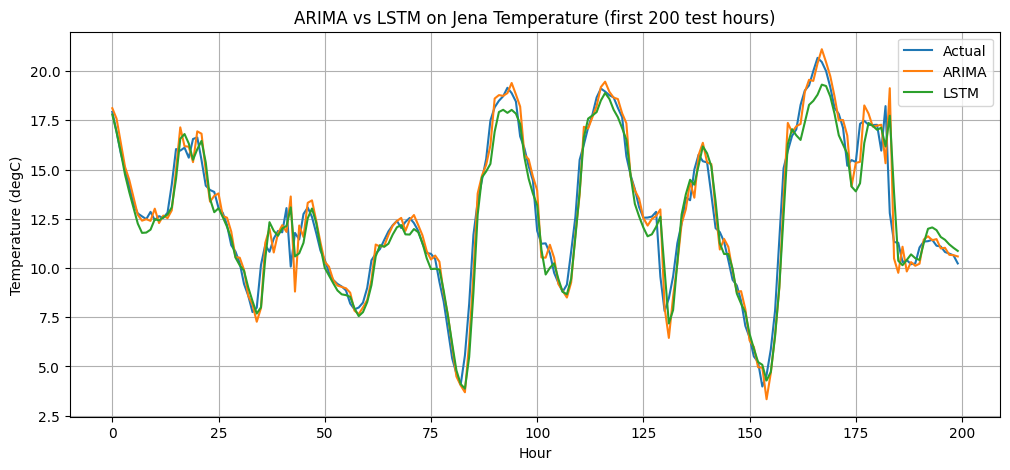

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from statsmodels.tsa.arima.model import ARIMA

df = pd.read_csv("Datasets/jena_climate_2009_2016.csv")
series = df["T (degC)"].values[5::6]

s = int(0.8 * len(series))
train = series[:s]
test = series[s:]
print("Hourly records:", len(series), " Training:", len(train), " Testing:", len(test))

arima = ARIMA(train, order=(2, 1, 1)).fit()
pred_arima = arima.append(test).predict(start=s)
rmse_arima = np.sqrt(np.mean((test - pred_arima) ** 2))

mean = train.mean()
std = train.std()
scaled = ((series - mean) / std).astype("float32")

steps = 24
X = []
Y = []
for i in range(len(scaled) - steps):
    X.append(scaled[i:i + steps])
    Y.append(scaled[i + steps])
X = torch.tensor(np.array(X)).unsqueeze(-1)
Y = torch.tensor(np.array(Y))

cut = s - steps
Xtr, Ytr = X[:cut], Y[:cut]
Xte = X[cut:]

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"


class Forecaster(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(1, 24, batch_first=True)
        self.fc = nn.Linear(24, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1]).squeeze(1)


model = Forecaster().to(device)
opt = torch.optim.Adam(model.parameters())
loss_fn = nn.MSELoss()

for epoch in range(3):
    perm = torch.randperm(len(Xtr))
    total = 0
    count = 0
    for i in range(0, len(Xtr), 128):
        idx = perm[i:i + 128]
        xb = Xtr[idx].to(device)
        yb = Ytr[idx].to(device)
        loss = loss_fn(model(xb), yb)
        opt.zero_grad()
        loss.backward()
        opt.step()
        total += loss.item()
        count += 1
    print("Epoch", epoch + 1, " Loss =", round(total / count, 5))

preds = []
with torch.no_grad():
    for i in range(0, len(Xte), 256):
        preds.append(model(Xte[i:i + 256].to(device)).cpu())
pred_lstm = torch.cat(preds).numpy() * std + mean
rmse_lstm = np.sqrt(np.mean((test - pred_lstm) ** 2))

print("ARIMA(2,1,1) RMSE:", round(rmse_arima, 3))
print("LSTM RMSE:", round(rmse_lstm, 3))

plt.figure(figsize=(12, 5))
plt.plot(test[:200], label="Actual")
plt.plot(pred_arima[:200], label="ARIMA")
plt.plot(pred_lstm[:200], label="LSTM")
plt.xlabel("Hour")
plt.ylabel("Temperature (degC)")
plt.title("ARIMA vs LSTM on Jena Temperature (first 200 test hours)")
plt.legend()
plt.grid(True)
plt.show()
